# Retail Demand Forecasting with Time Series Models
**Dataset:** Kaggle - Store Item Demand Forecasting Challenge (5 years of daily sales, 10 stores, 50 items, 913,000 rows)

## Business problem
A retail chain needs to forecast **total daily demand** so it can plan inventory and staffing. Under-forecasting causes stock-outs; over-forecasting causes waste and blocked cash.

## Approach
1. Explore the data (trend, yearly / weekly seasonality, stores, items)
2. Decompose the series and test stationarity (ADF, differencing, ACF / PACF)
3. Build baselines (Naive, Seasonal Naive) and statistical models (AR, MA, ARIMA, SARIMA, SARIMAX with Fourier terms)
4. Compare all models on a hold-out set using MAPE, RMSE and MAE
5. Validate the best model with walk-forward validation and residual diagnostics
6. Forecast the next 30 days with a 95% confidence interval

**Data file needed:** put `train.csv` in the same folder as this notebook.

## 1. Import libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox

from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error, mean_absolute_error

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
os.makedirs("outputs", exist_ok=True)

## 2. Load the dataset

In [2]:
df = pd.read_csv("train.csv", parse_dates=["date"])

print("Shape        :", df.shape)
print("Date range   :", df["date"].min().date(), "to", df["date"].max().date())
print("Stores       :", df["store"].nunique())
print("Items        :", df["item"].nunique())
print("Missing values:\n", df.isnull().sum())
df.head()

Shape        : (913000, 4)
Date range   : 2013-01-01 to 2017-12-31
Stores       : 10
Items        : 50
Missing values:
 date     0
store    0
item     0
sales    0
dtype: int64


,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


## 3. Pre-processing
The business question is about **total demand**, so we add up sales of all stores and items for each day, giving one daily time series. We also check that there are no missing days.

In [3]:
sales_ts = df.groupby("date")["sales"].sum().asfreq("D")

print("Days in series  :", len(sales_ts))
print("Missing days    :", sales_ts.isnull().sum())
print("Zero-sales days :", (sales_ts == 0).sum())
sales_ts.head()

Days in series  : 1826
Missing days    : 0
Zero-sales days : 0


date
2013-01-01    13696
2013-01-02    13678
2013-01-03    14488
2013-01-04    15677
2013-01-05    16237
Freq: D, Name: sales, dtype: int64

## 4. Exploratory Data Analysis

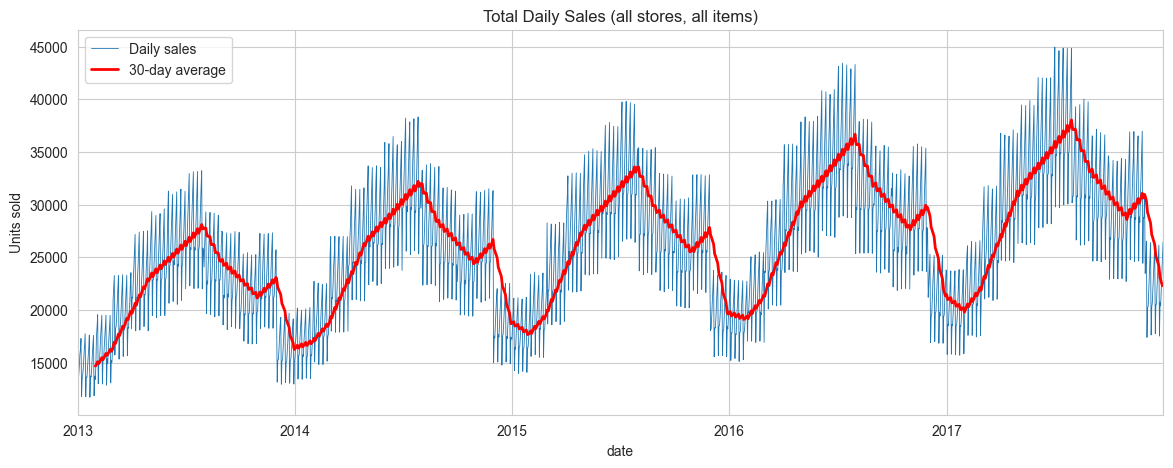

In [4]:
fig, ax = plt.subplots(figsize=(14, 5))
sales_ts.plot(ax=ax, lw=0.6, label="Daily sales")
sales_ts.rolling(30).mean().plot(ax=ax, color="red", lw=2, label="30-day average")
ax.set_title("Total Daily Sales (all stores, all items)")
ax.set_ylabel("Units sold")
ax.legend()
plt.show()

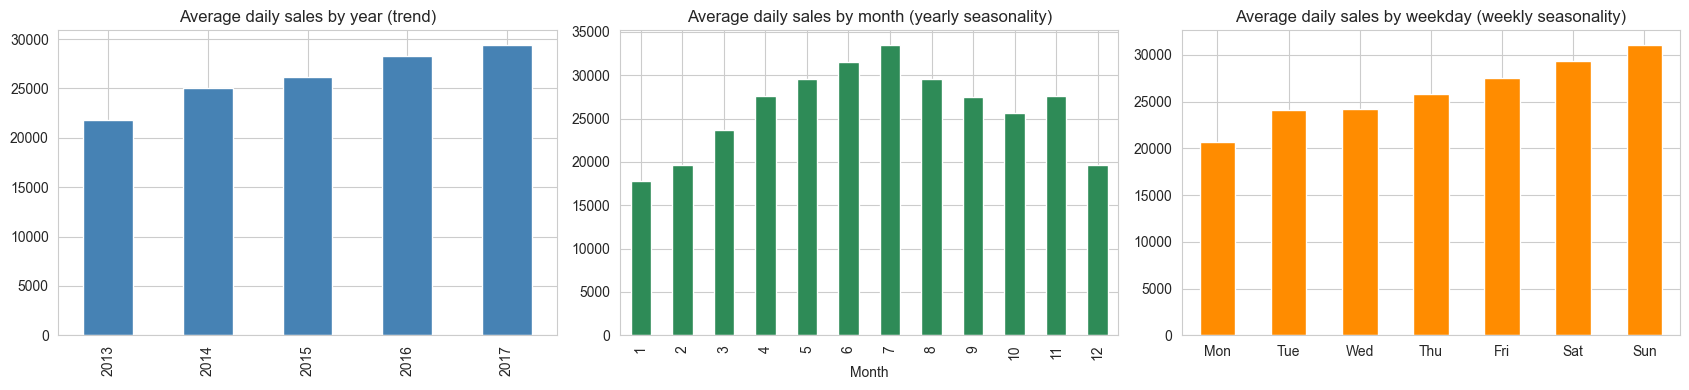

In [5]:
tmp = sales_ts.to_frame("sales")
tmp["year"] = tmp.index.year
tmp["month"] = tmp.index.month
tmp["dow"] = tmp.index.dayofweek

fig, axes = plt.subplots(1, 3, figsize=(17, 4))

tmp.groupby("year")["sales"].mean().plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Average daily sales by year (trend)")
axes[0].set_xlabel("")

tmp.groupby("month")["sales"].mean().plot(kind="bar", ax=axes[1], color="seagreen")
axes[1].set_title("Average daily sales by month (yearly seasonality)")
axes[1].set_xlabel("Month")

tmp.groupby("dow")["sales"].mean().plot(kind="bar", ax=axes[2], color="darkorange")
axes[2].set_title("Average daily sales by weekday (weekly seasonality)")
axes[2].set_xticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], rotation=0)
axes[2].set_xlabel("")

plt.tight_layout()
plt.show()

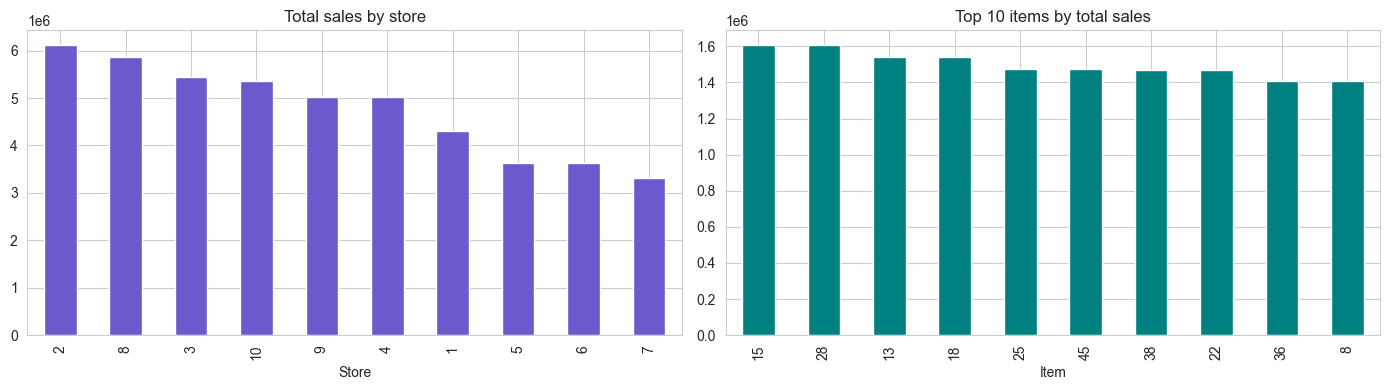

In [6]:
store_sales = df.groupby("store")["sales"].sum().sort_values(ascending=False)
item_sales = df.groupby("item")["sales"].sum().sort_values(ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
store_sales.plot(kind="bar", ax=axes[0], color="slateblue")
axes[0].set_title("Total sales by store")
axes[0].set_xlabel("Store")

item_sales.plot(kind="bar", ax=axes[1], color="teal")
axes[1].set_title("Top 10 items by total sales")
axes[1].set_xlabel("Item")

plt.tight_layout()
plt.show()

## 5. Time series decomposition (trend, seasonality, residual)

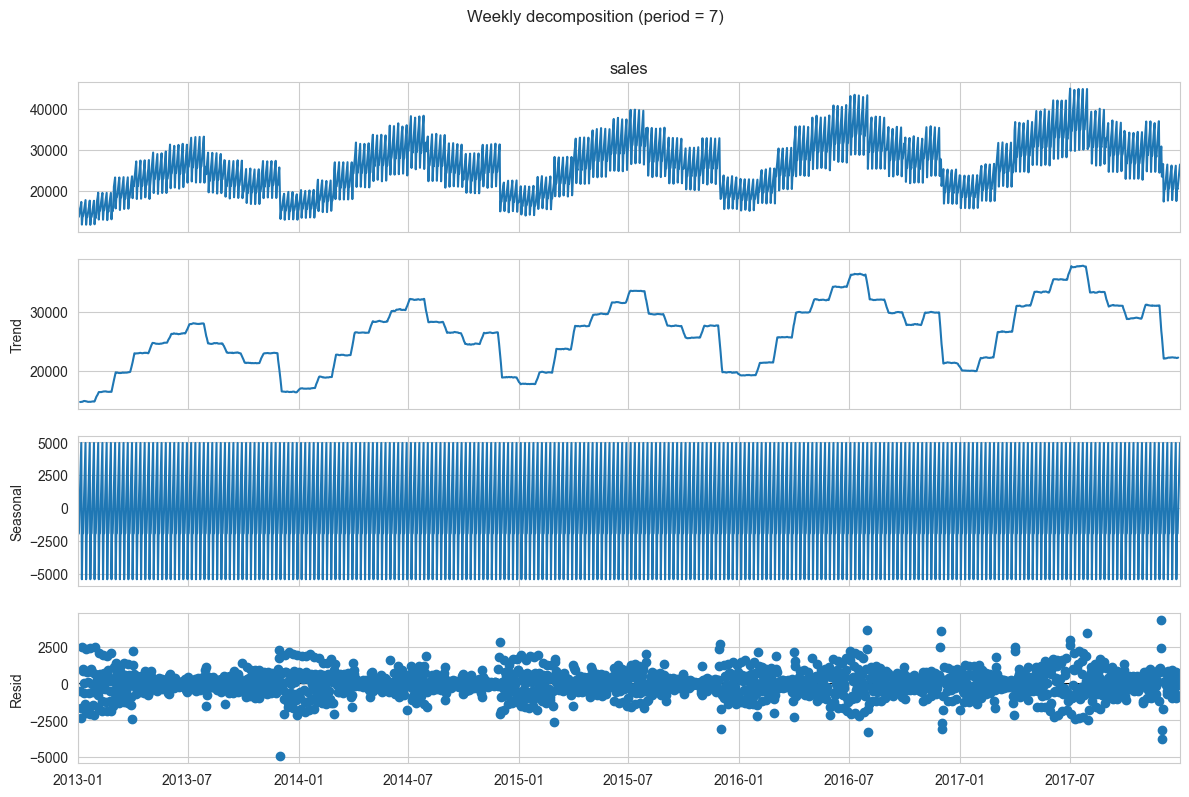

In [7]:
decomp_week = seasonal_decompose(sales_ts, model="additive", period=7)
fig = decomp_week.plot()
fig.set_size_inches(12, 8)
fig.suptitle("Weekly decomposition (period = 7)", y=1.02)
plt.show()

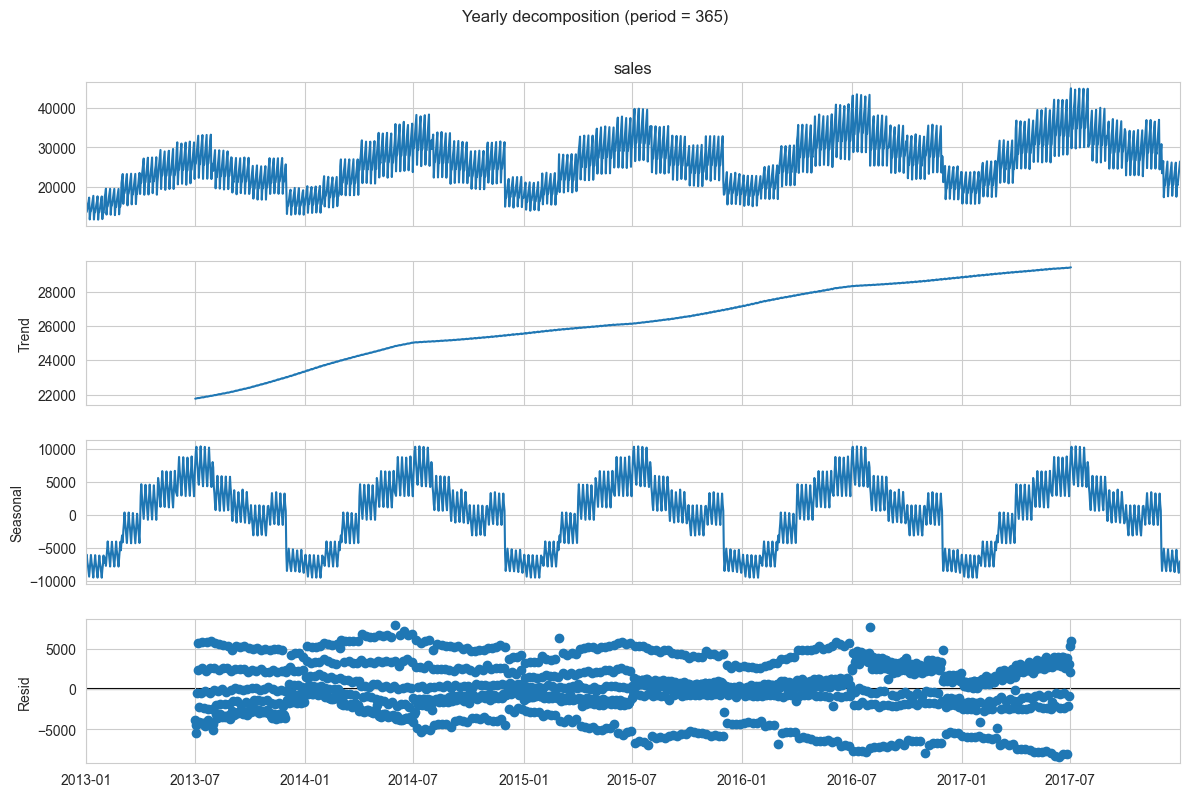

In [8]:
decomp_year = seasonal_decompose(sales_ts, model="additive", period=365)
fig = decomp_year.plot()
fig.set_size_inches(12, 8)
fig.suptitle("Yearly decomposition (period = 365)", y=1.02)
plt.show()

## 6. Stationarity check

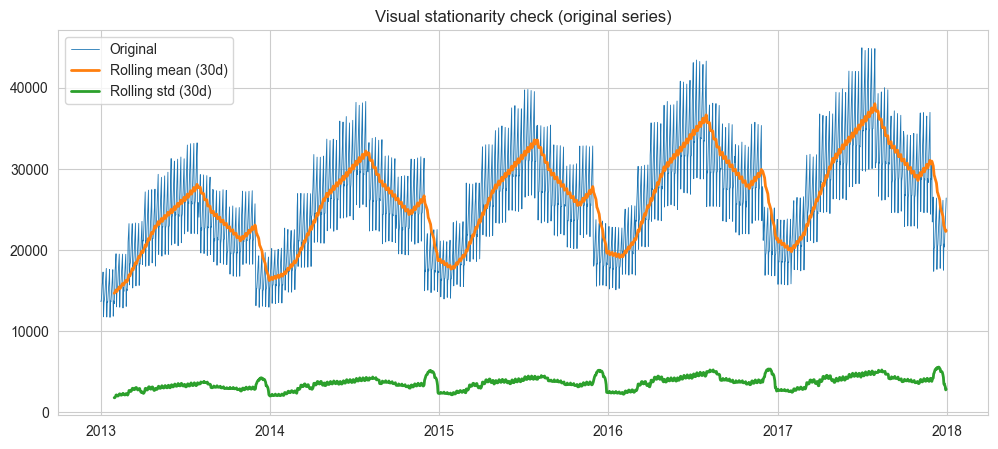

Original series        ADF stat =   -3.060 | p-value = 0.0296 -> Stationary


In [9]:
def adf_report(series, name=""):
    result = adfuller(series.dropna(), autolag="AIC")
    verdict = "Stationary" if result[1] < 0.05 else "Non-stationary"
    print(f"{name:<22} ADF stat = {result[0]:8.3f} | p-value = {result[1]:.4f} -> {verdict}")

rolling_mean = sales_ts.rolling(30).mean()
rolling_std = sales_ts.rolling(30).std()

plt.figure(figsize=(12, 5))
plt.plot(sales_ts, label="Original", lw=0.6)
plt.plot(rolling_mean, label="Rolling mean (30d)", lw=2)
plt.plot(rolling_std, label="Rolling std (30d)", lw=2)
plt.title("Visual stationarity check (original series)")
plt.legend()
plt.show()

adf_report(sales_ts, "Original series")

The rolling mean rises over time, so the series has a trend and is not stationary. We apply first-order differencing.

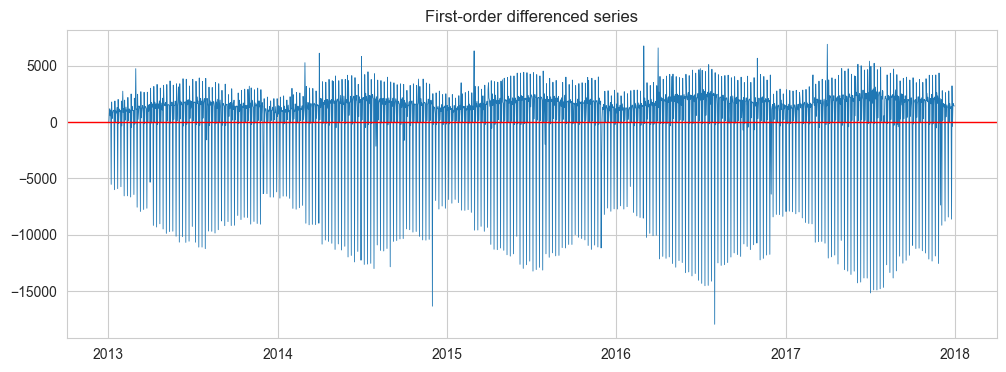

Differenced (d=1)      ADF stat =   -8.919 | p-value = 0.0000 -> Stationary


In [10]:
sales_diff = sales_ts.diff().dropna()

plt.figure(figsize=(12, 4))
plt.plot(sales_diff, lw=0.6)
plt.axhline(0, color="red", lw=1)
plt.title("First-order differenced series")
plt.show()

adf_report(sales_diff, "Differenced (d=1)")

## 7. ACF and PACF (guide for choosing model orders)

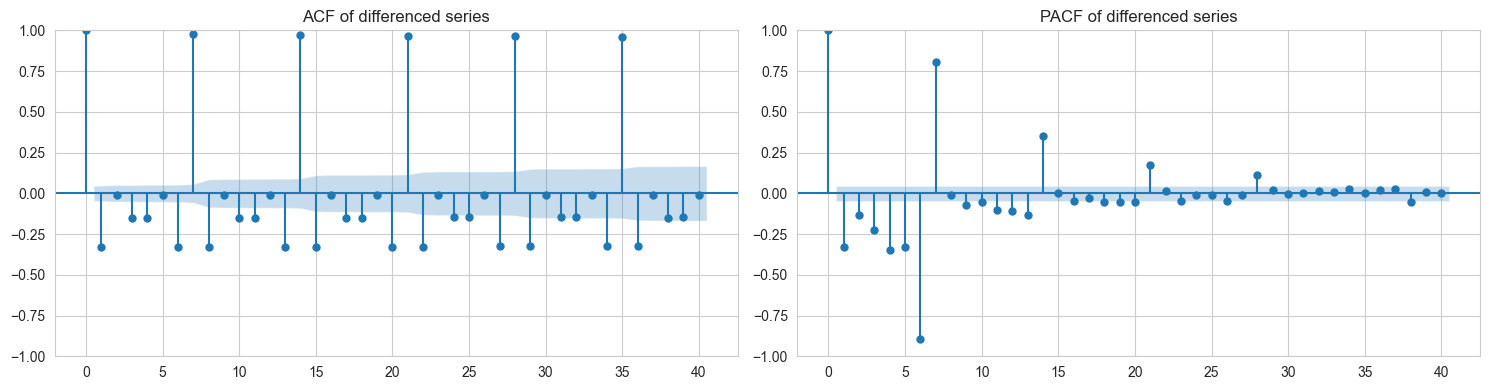

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
plot_acf(sales_diff, lags=40, ax=axes[0])
plot_pacf(sales_diff, lags=40, ax=axes[1], method="ywm")
axes[0].set_title("ACF of differenced series")
axes[1].set_title("PACF of differenced series")
plt.tight_layout()
plt.show()

Spikes at lags 7, 14, 21 ... in the ACF confirm a **weekly seasonal cycle**. That is why we use order 7 for AR / MA and a seasonal period of 7 in SARIMA.

## 8. Train / test split
The last **90 days** are kept as the hold-out test set (the same horizon as the original Kaggle challenge).

In [12]:
TEST_DAYS = 90
train = sales_ts.iloc[:-TEST_DAYS]
test = sales_ts.iloc[-TEST_DAYS:]

print("Train:", train.index.min().date(), "to", train.index.max().date(), f"({len(train)} days)")
print("Test :", test.index.min().date(), "to", test.index.max().date(), f"({len(test)} days)")

Train: 2013-01-01 to 2017-10-02 (1736 days)
Test : 2017-10-03 to 2017-12-31 (90 days)


## 9. Models
All models are evaluated on the **original sales scale**, so their errors are directly comparable.

- **Naive** - repeats the last value
- **Seasonal Naive** - repeats the last 7 days
- **AR(7)** - `ARIMA(7,1,0)`: autoregressive model on the differenced series
- **MA(7)** - `ARIMA(0,1,7)`: moving average model on the differenced series
- **ARIMA(2,1,2)** - combined AR + MA on the differenced series
- **SARIMA** - adds a weekly seasonal component
- **SARIMAX + Fourier** - SARIMA plus Fourier terms that capture the **yearly** seasonality (SARIMA with period 7 cannot see it)

In [13]:
def fourier_terms(index, K=3, period=365.25):
    # Sine / cosine terms that model the yearly cycle
    t = np.asarray((index - pd.Timestamp("2013-01-01")).days)
    cols = {}
    for k in range(1, K + 1):
        cols[f"sin{k}"] = np.sin(2 * np.pi * k * t / period)
        cols[f"cos{k}"] = np.cos(2 * np.pi * k * t / period)
    return pd.DataFrame(cols, index=index)


MODELS = ["Naive", "Seasonal Naive", "AR(7)", "MA(7)", "ARIMA(2,1,2)",
          "SARIMA(1,1,1)(1,1,1,7)", "SARIMAX + Fourier"]


def fit_and_forecast(name, y, steps, alpha=0.05):
    # Fit one model on series y and forecast `steps` days ahead.
    # Returns: fitted model (None for baselines), forecast Series, confidence interval DataFrame (None for baselines)
    future_index = pd.date_range(y.index[-1] + pd.Timedelta(days=1), periods=steps, freq="D")

    if name == "Naive":
        return None, pd.Series(y.iloc[-1], index=future_index), None

    if name == "Seasonal Naive":
        last_week = y.iloc[-7:].values
        values = np.tile(last_week, int(np.ceil(steps / 7)))[:steps]
        return None, pd.Series(values, index=future_index), None

    if name == "AR(7)":
        model = ARIMA(y, order=(7, 1, 0)).fit()
        fc = model.get_forecast(steps=steps)
    elif name == "MA(7)":
        model = ARIMA(y, order=(0, 1, 7)).fit()
        fc = model.get_forecast(steps=steps)
    elif name == "ARIMA(2,1,2)":
        model = ARIMA(y, order=(2, 1, 2)).fit()
        fc = model.get_forecast(steps=steps)
    elif name == "SARIMA(1,1,1)(1,1,1,7)":
        model = SARIMAX(y, order=(1, 1, 1), seasonal_order=(1, 1, 1, 7)).fit(disp=False, maxiter=200)
        fc = model.get_forecast(steps=steps)
    elif name == "SARIMAX + Fourier":
        model = SARIMAX(y, exog=fourier_terms(y.index), order=(1, 1, 1),
                        seasonal_order=(1, 1, 1, 7)).fit(disp=False, maxiter=200)
        fc = model.get_forecast(steps=steps, exog=fourier_terms(future_index))
    else:
        raise ValueError(name)

    mean = pd.Series(np.asarray(fc.predicted_mean), index=future_index)
    ci = pd.DataFrame(np.asarray(fc.conf_int(alpha=alpha)), index=future_index, columns=["lower", "upper"])
    return model, mean, ci

In [14]:
results = {}
forecasts = {}
fitted = {}

def evaluate(name, actual, pred):
    results[name] = {
        "MAPE (%)": mean_absolute_percentage_error(actual, pred) * 100,
        "RMSE": np.sqrt(mean_squared_error(actual, pred)),
        "MAE": mean_absolute_error(actual, pred),
    }
    forecasts[name] = pred

for name in MODELS:
    start = time.time()
    model, pred, _ = fit_and_forecast(name, train, len(test))
    evaluate(name, test, pred)
    if model is not None:
        fitted[name] = model
    print(f"{name:<26} done in {time.time() - start:5.1f}s | MAPE = {results[name]['MAPE (%)']:.2f}%")

Naive                      done in   0.0s | MAPE = 18.37%
Seasonal Naive             done in   0.0s | MAPE = 15.37%
AR(7)                      done in   1.9s | MAPE = 13.41%


C:\Users\ADMIN\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
C:\Users\ADMIN\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\ADMIN\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


MA(7)                      done in   4.3s | MAPE = 16.54%


C:\Users\ADMIN\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


ARIMA(2,1,2)               done in   2.0s | MAPE = 20.43%
SARIMA(1,1,1)(1,1,1,7)     done in   2.9s | MAPE = 14.53%
SARIMAX + Fourier          done in   6.1s | MAPE = 7.20%


## 10. Model comparison

In [15]:
results_df = pd.DataFrame(results).T.sort_values("MAPE (%)").round(2)
results_df.to_csv("outputs/model_comparison.csv")
results_df

,MAPE (%),RMSE,MAE
SARIMAX + Fourier,7.20,2349.49,1954.50
AR(7),13.41,4213.82,3231.06
"SARIMA(1,1,1)(1,1,1,7)",14.53,4873.62,3420.88
Seasonal Naive,15.37,5050.29,3634.17
MA(7),16.54,5018.63,4097.97
Naive,18.37,6640.37,5402.10
"ARIMA(2,1,2)",20.43,5881.12,4862.32


Best model overall      : SARIMAX + Fourier
Best statistical model  : SARIMAX + Fourier


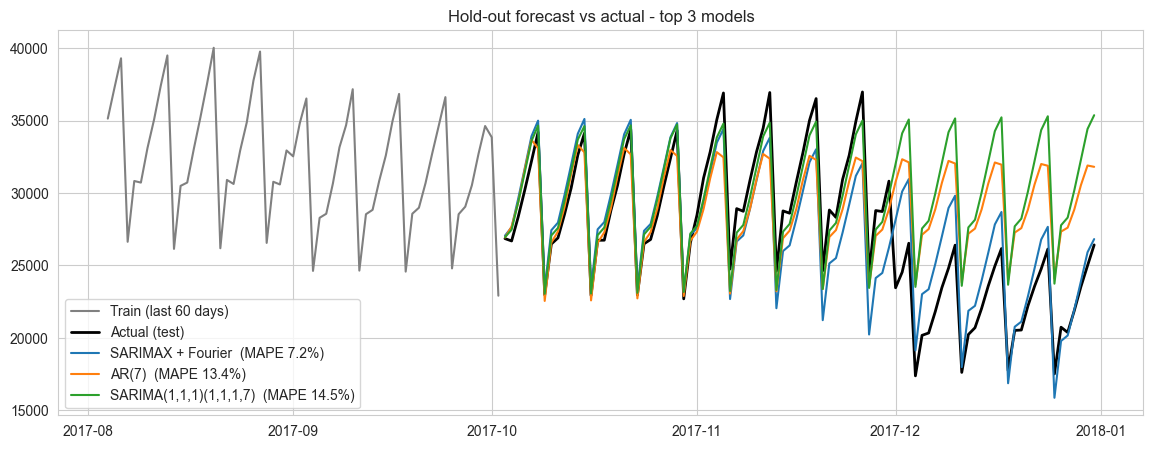

In [16]:
best_overall = results_df.index[0]
best_stat = next(n for n in results_df.index if n in fitted)   # best model that is not a baseline

print("Best model overall      :", best_overall)
print("Best statistical model  :", best_stat)

top = list(results_df.index[:3])
plt.figure(figsize=(14, 5))
plt.plot(train.iloc[-60:], color="grey", label="Train (last 60 days)")
plt.plot(test, color="black", lw=2, label="Actual (test)")
for n in top:
    plt.plot(forecasts[n], lw=1.5, label=f"{n}  (MAPE {results[n]['MAPE (%)']:.1f}%)")
plt.title("Hold-out forecast vs actual - top 3 models")
plt.legend()
plt.savefig("outputs/model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. Residual diagnostics of the best statistical model

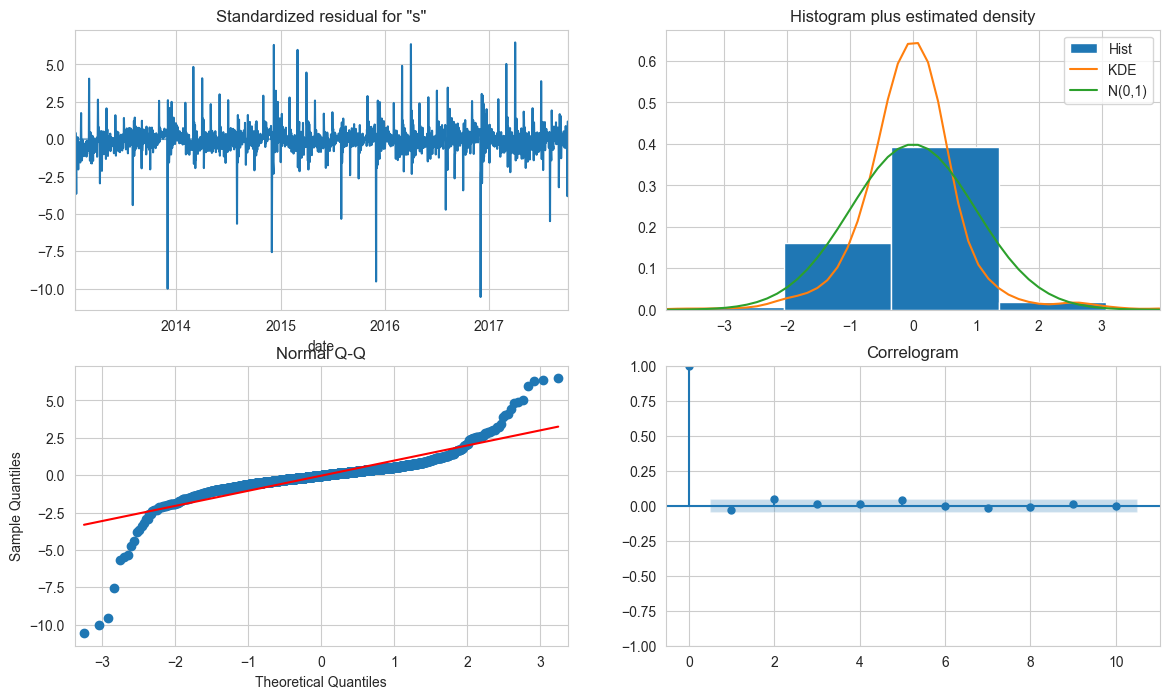

Ljung-Box test (p > 0.05 means no leftover autocorrelation):
    lb_stat  lb_pvalue
7   10.5274     0.1606
14  15.1109     0.3706
21  24.9921     0.2475


In [17]:
best_model = fitted[best_stat]

fig = best_model.plot_diagnostics(figsize=(14, 8))
plt.show()

lb = acorr_ljungbox(best_model.resid.iloc[14:], lags=[7, 14, 21], return_df=True)
print("Ljung-Box test (p > 0.05 means no leftover autocorrelation):")
print(lb.round(4))

## 12. Walk-forward validation
A single train / test split can be lucky. Here the model is re-fitted 4 times, each time forecasting the next 30 days from a later starting point, and compared with the Seasonal Naive baseline.

In [18]:
HORIZON = 30
FOLDS = 4
n = len(sales_ts)
rows = []

for i in range(FOLDS):
    cut = n - HORIZON * (FOLDS - i)
    y_train = sales_ts.iloc[:cut]
    y_true = sales_ts.iloc[cut:cut + HORIZON]

    _, pred_best, _ = fit_and_forecast(best_stat, y_train, HORIZON)
    _, pred_base, _ = fit_and_forecast("Seasonal Naive", y_train, HORIZON)

    rows.append({
        "Fold": i + 1,
        "Forecast period": f"{y_true.index[0].date()} to {y_true.index[-1].date()}",
        f"MAPE % ({best_stat})": mean_absolute_percentage_error(y_true, pred_best) * 100,
        "MAPE % (Seasonal Naive)": mean_absolute_percentage_error(y_true, pred_base) * 100,
    })

wf = pd.DataFrame(rows).round(2)
wf.to_csv("outputs/walk_forward_validation.csv", index=False)
print(wf.to_string(index=False))
print()
print(wf.drop(columns=["Fold", "Forecast period"]).mean().round(2).to_string())

 Fold          Forecast period  MAPE % (SARIMAX + Fourier)  MAPE % (Seasonal Naive)
    1 2017-09-03 to 2017-10-02                        2.31                     6.24
    2 2017-10-03 to 2017-11-01                        3.45                     5.44
    3 2017-11-02 to 2017-12-01                        8.03                     7.29
    4 2017-12-02 to 2017-12-31                        7.51                    34.98

MAPE % (SARIMAX + Fourier)     5.32
MAPE % (Seasonal Naive)       13.49


## 13. Final forecast - next 30 days

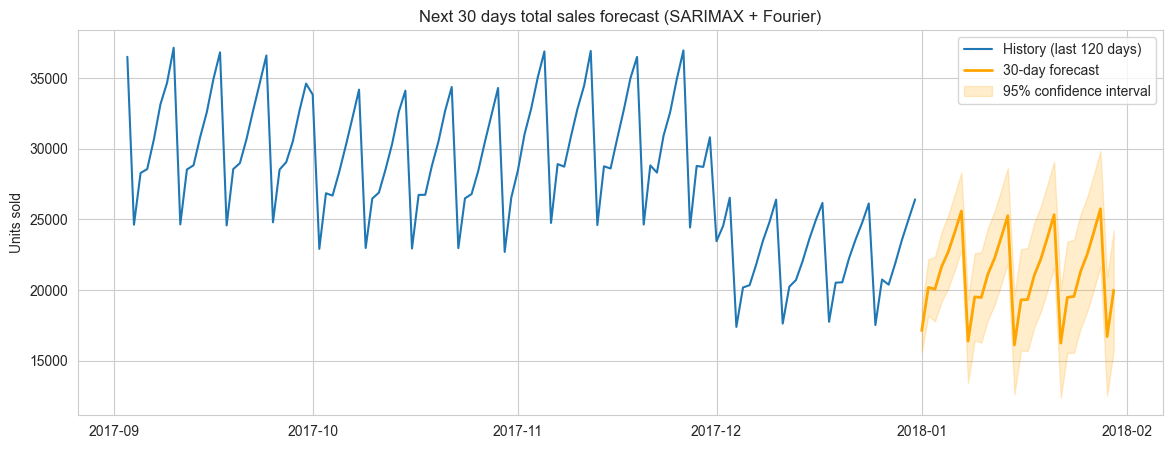

,forecast,lower,upper
2018-01-01,17123.0,15603.0,18643.0
2018-01-02,20178.0,18181.0,22176.0
2018-01-03,20062.0,17779.0,22344.0
2018-01-04,21647.0,19178.0,24117.0
2018-01-05,22697.0,20099.0,25294.0
2018-01-06,24107.0,21421.0,26793.0
2018-01-07,25591.0,22842.0,28340.0
2018-01-08,16374.0,13421.0,19327.0
2018-01-09,19509.0,16416.0,22603.0
2018-01-10,19471.0,16279.0,22663.0


In [19]:
final_model, future, ci = fit_and_forecast(best_stat, sales_ts, 30)

plt.figure(figsize=(14, 5))
plt.plot(sales_ts.iloc[-120:], label="History (last 120 days)")
plt.plot(future, color="orange", lw=2, label="30-day forecast")
plt.fill_between(ci.index, ci["lower"], ci["upper"], color="orange", alpha=0.2, label="95% confidence interval")
plt.title(f"Next 30 days total sales forecast ({best_stat})")
plt.ylabel("Units sold")
plt.legend()
plt.savefig("outputs/final_forecast.png", dpi=150, bbox_inches="tight")
plt.show()

forecast_table = pd.concat([future.rename("forecast"), ci], axis=1).round(0)
forecast_table.to_csv("outputs/forecast_next_30_days.csv")
forecast_table.head(10)

## 14. Business insights

In [20]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

dow_avg = tmp.groupby("dow")["sales"].mean()
month_avg = tmp.groupby("month")["sales"].mean()
year_avg = tmp.groupby("year")["sales"].mean()
cagr = (year_avg.iloc[-1] / year_avg.iloc[0]) ** (1 / (len(year_avg) - 1)) - 1

print(f"Busiest weekday   : {days[dow_avg.idxmax()]} ({dow_avg.max() / dow_avg.mean() - 1:+.1%} vs average day)")
print(f"Quietest weekday  : {days[dow_avg.idxmin()]} ({dow_avg.min() / dow_avg.mean() - 1:+.1%} vs average day)")
print(f"Peak month        : {months[month_avg.idxmax() - 1]} ({month_avg.max() / month_avg.mean() - 1:+.1%} vs average month)")
print(f"Lowest month      : {months[month_avg.idxmin() - 1]} ({month_avg.min() / month_avg.mean() - 1:+.1%} vs average month)")
print(f"Yearly growth     : {cagr:.1%} per year (average daily sales, {year_avg.index[0]} to {year_avg.index[-1]})")
print(f"Best store        : Store {store_sales.index[0]} | Weakest store: Store {store_sales.index[-1]}")
print(f"Best model        : {best_stat} (hold-out MAPE {results[best_stat]['MAPE (%)']:.2f}%)")

Busiest weekday   : Sunday (+18.9% vs average day)
Quietest weekday  : Monday (-20.7% vs average day)
Peak month        : Jul (+28.3% vs average month)
Lowest month      : Jan (-32.0% vs average month)
Yearly growth     : 7.8% per year (average daily sales, 2013 to 2017)
Best store        : Store 2 | Weakest store: Store 7
Best model        : SARIMAX + Fourier (hold-out MAPE 7.20%)


## 15. Conclusion, limitations and next steps
- The series has a clear **upward trend**, a **weekly cycle** and a **yearly cycle**. A model that captures all three performs best.
- Models were compared on the same hold-out set and re-checked with walk-forward validation, and the final forecast includes a 95% confidence interval.
- **Limitations:** the forecast is for total sales only (no store or item level), and holidays and promotions are not available in this dataset.
- **Next steps:** forecast per store or item (hierarchical forecasting), compare with Prophet or gradient boosting with lag features, and wrap the final model in a Streamlit app.